# Projeto de IA — Modelagem de Ciclos de Atividade Solar
## Notebook 03 — Construção e avaliação de um modelo ARIMA

**Objetivo desta etapa:** construir um modelo ARIMA para a série anual de números de manchas solares, selecionar seus parâmetros usando somente os dados de treinamento, analisar os resíduos e avaliar previsões fora da amostra.

Este notebook dá continuidade aos Notebooks 01 e 02. A base principal continua sendo `sunspots` do Statsmodels (1700–2008). O foco agora é a modelagem, não a busca de uma explicação física completa para o ciclo solar.

> **Decisão de avaliação:** os últimos 40 anos (1969–2008) serão reservados para teste. A seleção do modelo será feita somente com os anos anteriores. Na avaliação, usaremos previsões de um passo à frente: a cada novo ano, o modelo poderá incorporar o valor real do ano anterior, mas nunca valores futuros.

## 1. Preparação do ambiente

Instale as bibliotecas no terminal, caso ainda não estejam disponíveis:

```bash
python -m pip install numpy pandas matplotlib scipy statsmodels scikit-learn jupyter
```

O notebook usa o dataset disponibilizado pelo Statsmodels; portanto, não depende do arquivo TXT para executar.

In [14]:
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.datasets import sunspots
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

SEMENTE = 42
np.random.seed(SEMENTE)
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Carregamento e preparação da série

A série tem uma observação por ano. Para o ARIMA, usaremos os valores numéricos em ordem cronológica. Guardamos os anos separadamente para facilitar a leitura dos gráficos e das tabelas.

In [15]:
dados = sunspots.load_pandas().data.copy()
dados = dados.rename(columns={"YEAR": "ano", "SUNACTIVITY": "manchas"})
dados["ano"] = dados["ano"].astype(int)
dados["manchas"] = dados["manchas"].astype(float)
dados = dados.sort_values("ano").reset_index(drop=True)

serie = dados.set_index("ano")["manchas"]

print(f"Período: {serie.index.min()}–{serie.index.max()}")
print(f"Número de observações: {len(serie)}")
print(f"Frequência observacional: anual")
print(f"Valores ausentes: {serie.isna().sum()}")
display(dados.head())
display(dados.tail())

Período: 1700–2008
Número de observações: 309
Frequência observacional: anual
Valores ausentes: 0


,ano,manchas
0,1700,5.0
1,1701,11.0
2,1702,16.0
3,1703,23.0
4,1704,36.0


,ano,manchas
304,2004,40.4
305,2005,29.8
306,2006,15.2
307,2007,7.5
308,2008,2.9


## 3. Separação cronológica entre treino e teste

Não faremos divisão aleatória. Em séries temporais, embaralhar as observações permitiria que o treinamento usasse anos posteriores aos anos avaliados, criando **vazamento de informação (data leakage)**.

A configuração padrão reserva os últimos 40 anos para teste. Como a base termina em 2008, o intervalo de teste deverá ser 1969–2008. O parâmetro abaixo pode ser alterado, mas a decisão deve ser registrada no relatório.

Treino: 1700–1968 (269 observações)
Teste:  1969–2008 (40 observações)


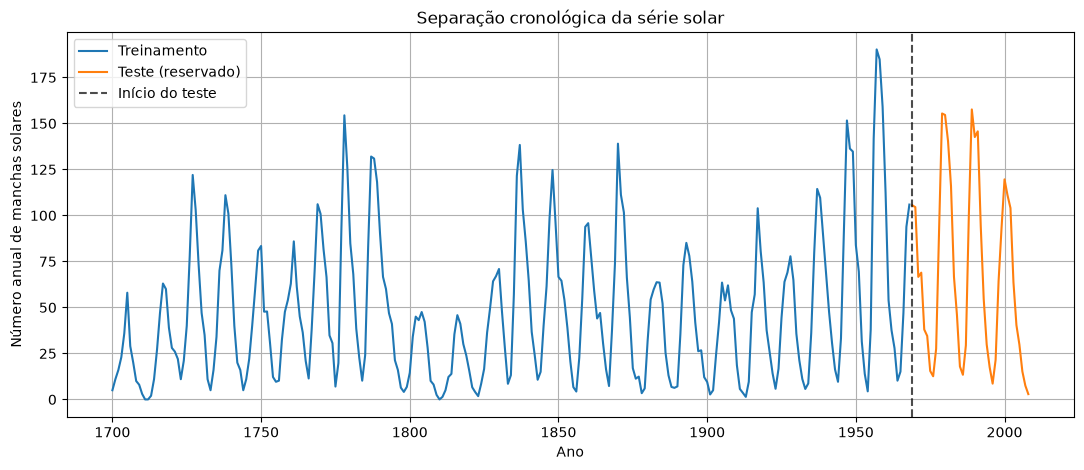

In [16]:
N_ANOS_TESTE = 40

if N_ANOS_TESTE <= 0 or N_ANOS_TESTE >= len(serie):
    raise ValueError("N_ANOS_TESTE deve ser positivo e menor que o tamanho da série.")

treino = serie.iloc[:-N_ANOS_TESTE].copy()
teste = serie.iloc[-N_ANOS_TESTE:].copy()

print(f"Treino: {treino.index.min()}–{treino.index.max()} ({len(treino)} observações)")
print(f"Teste:  {teste.index.min()}–{teste.index.max()} ({len(teste)} observações)")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(treino.index, treino.values, label="Treinamento")
ax.plot(teste.index, teste.values, label="Teste (reservado)")
ax.axvline(teste.index.min(), color="black", linestyle="--", alpha=0.7, label="Início do teste")
ax.set(title="Separação cronológica da série solar", xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.show()

### Por que não usar o teste para escolher o modelo?

O conjunto de teste representa o futuro que o modelo ainda não conhece. Se escolhermos `p`, `d` ou `q` observando qual combinação tem o melhor resultado nesse conjunto, o teste deixa de ser uma avaliação independente.

Nesta etapa, os parâmetros serão escolhidos com base no AIC calculado no treino. O teste será usado somente depois, para estimar o desempenho preditivo. Em um estudo mais avançado, também poderíamos separar uma validação dentro do próprio treino.

## 4. O que significam os parâmetros ARIMA(p, d, q)?

- **p (autorregressivo):** quantos valores passados da série entram diretamente no modelo.
- **d (diferenciação):** quantas vezes a série é diferenciada para tratar tendência ou não estacionariedade.
- **q (média móvel):** quantos erros passados entram na estrutura do modelo.

O Notebook 02 encontrou evidências que merecem investigação: ADF e KPSS têm hipóteses nulas diferentes e seus resultados na série original não foram perfeitamente concordantes. Por isso, não devemos transformar um único p-valor em certeza. Aqui testaremos `d=0` e `d=1` em candidatos ajustados somente no treino.

O ARIMA não modela automaticamente um ciclo físico fixo de 11 anos como um mecanismo astronômico. Ele representa dependências estatísticas temporais. A capacidade de acompanhar os ciclos será verificada pelos resíduos e pelas previsões.

## 5. Busca de ordens candidatas pelo AIC (somente no treino)

Vamos testar combinações pequenas de `p`, `d` e `q`. Para manter o exercício compreensível e o tempo de execução razoável, o padrão é `p` e `q` entre 0 e 4 e `d` em {0, 1}.

**AIC** combina ajuste e penalização pela quantidade de parâmetros; valores menores indicam melhor compromisso dentro do conjunto de candidatos ajustados. O AIC não garante boa previsão e não deve ser interpretado isoladamente. A comparação entre modelos com diferentes ordens de diferenciação também exige cautela, pois o tratamento da amostra efetiva pode variar.

In [17]:
MAX_P = 4
MAX_Q = 4
VALORES_D = [0, 1]

resultados_busca = []
falhas_busca = []

# Desativamos avisos numéricos repetitivos durante a busca; falhas são registradas.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for p, d, q in product(range(MAX_P + 1), VALORES_D, range(MAX_Q + 1)):
        ordem = (p, d, q)
        try:
            ajuste = ARIMA(
                treino.to_numpy(),
                order=ordem,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(method_kwargs={"maxiter": 200})
            resultados_busca.append({
                "ordem": ordem,
                "p": p, "d": d, "q": q,
                "AIC": float(ajuste.aic),
                "BIC": float(ajuste.bic),
                "convergiu": getattr(ajuste, "mle_retvals", {}).get("converged", np.nan)
            })
        except Exception as erro:
            falhas_busca.append({"ordem": ordem, "erro": str(erro)[:250]})

if not resultados_busca:
    raise RuntimeError("Nenhum modelo ARIMA foi ajustado. Verifique os dados e a instalação do Statsmodels.")

tabela_busca = pd.DataFrame(resultados_busca).sort_values("AIC").reset_index(drop=True)
print(f"Modelos ajustados: {len(tabela_busca)} | Falhas: {len(falhas_busca)}")
display(tabela_busca.head(15).round(3))

# Não aceitamos automaticamente um ajuste que o otimizador marcou como não convergido.
convergentes = tabela_busca[tabela_busca["convergiu"] == True]
if len(convergentes) > 0:
    linha_escolhida = convergentes.iloc[0]
    criterio_escolha = "menor AIC entre os modelos com convergência reportada"
else:
    # Fallback transparente: se nenhum convergir, o menor AIC é apenas um candidato
    # e precisa de investigação antes de ser considerado um resultado confiável.
    linha_escolhida = tabela_busca.iloc[0]
    criterio_escolha = "menor AIC geral (ATENÇÃO: nenhum candidato reportou convergência)"

ordem_escolhida = tuple(linha_escolhida["ordem"])
tabela_busca["selecionado"] = tabela_busca["ordem"].apply(lambda ordem: tuple(ordem) == ordem_escolhida)
print("Menor AIC geral:", tuple(tabela_busca.iloc[0]["ordem"]), "| convergiu:", tabela_busca.iloc[0]["convergiu"])
print("Ordem escolhida:", ordem_escolhida)
print("Critério:", criterio_escolha)
print("AIC da ordem escolhida:", round(float(linha_escolhida["AIC"]), 3))
display(tabela_busca.head(15).round(3))

Modelos ajustados: 50 | Falhas: 0


,ordem,p,d,q,AIC,BIC,convergiu
0,"(4, 1, 4)",4,1,4,2187.535,2219.684,True
1,"(3, 1, 4)",3,1,4,2188.971,2217.548,True
2,"(2, 1, 4)",2,1,4,2190.533,2215.538,True
3,"(4, 0, 4)",4,0,4,2190.905,2226.665,True
4,"(3, 0, 4)",3,0,4,2192.453,2224.637,True
5,"(2, 1, 3)",2,1,3,2196.680,2218.135,True
6,"(3, 1, 3)",3,1,3,2205.951,2230.983,True
7,"(3, 1, 2)",3,1,2,2206.070,2227.549,True
8,"(4, 1, 3)",4,1,3,2207.257,2235.865,True
9,"(2, 0, 4)",2,0,4,2208.923,2237.531,True


Menor AIC geral: (4, 1, 4) | convergiu: True
Ordem escolhida: (4, 1, 4)
Critério: menor AIC entre os modelos com convergência reportada
AIC da ordem escolhida: 2187.535


,ordem,p,d,q,AIC,BIC,convergiu,selecionado
0,"(4, 1, 4)",4,1,4,2187.535,2219.684,True,True
1,"(3, 1, 4)",3,1,4,2188.971,2217.548,True,False
2,"(2, 1, 4)",2,1,4,2190.533,2215.538,True,False
3,"(4, 0, 4)",4,0,4,2190.905,2226.665,True,False
4,"(3, 0, 4)",3,0,4,2192.453,2224.637,True,False
5,"(2, 1, 3)",2,1,3,2196.680,2218.135,True,False
6,"(3, 1, 3)",3,1,3,2205.951,2230.983,True,False
7,"(3, 1, 2)",3,1,2,2206.070,2227.549,True,False
8,"(4, 1, 3)",4,1,3,2207.257,2235.865,True,False
9,"(2, 0, 4)",2,0,4,2208.923,2237.531,True,False


### Interpretação da busca

1. A primeira linha da tabela tem o menor AIC geral, mas pode não ter convergido.
2. A ordem escolhida automaticamente é o menor AIC entre os candidatos com convergência reportada. Verifique a coluna `selecionado`.
3. Compare AIC e BIC, mas não os trate como prova de superioridade preditiva.
4. Observe também se a ordem escolhida está no limite da faixa pesquisada (`MAX_P` ou `MAX_Q`). Se estiver, isso sugere ampliar a busca em outra rodada, sempre usando apenas o treino.
5. A ordem escolhida é provisória: a análise dos resíduos e o desempenho no teste ainda precisam ser considerados.

In [18]:
# Reajusta a ordem selecionada no conjunto completo de treinamento.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_treino = ARIMA(
        treino.to_numpy(),
        order=ordem_escolhida,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(method_kwargs={"maxiter": 200})

print(modelo_treino.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  269
Model:                 ARIMA(4, 1, 4)   Log Likelihood               -1084.767
Date:                Fri, 13 Nov 2026   AIC                           2187.535
Time:                        19:02:06   BIC                           2219.684
Sample:                             0   HQIC                          2200.455
                                - 269                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4190      0.166      2.517      0.012       0.093       0.745
ar.L2          0.3546      0.175      2.030      0.042       0.012       0.697
ar.L3         -0.0852      0.203     -0.420      0.6

## 6. Diagnóstico dos resíduos

Resíduo é a diferença entre o valor observado e o valor ajustado pelo modelo. Um bom modelo deve deixar resíduos sem padrões temporais importantes. Isso não significa que eles precisem ser perfeitamente normais, mas autocorrelação remanescente é um sinal de que a estrutura temporal talvez não tenha sido capturada.

Examinaremos o gráfico temporal, a distribuição, o gráfico Q-Q, a ACF e o teste de Ljung–Box.

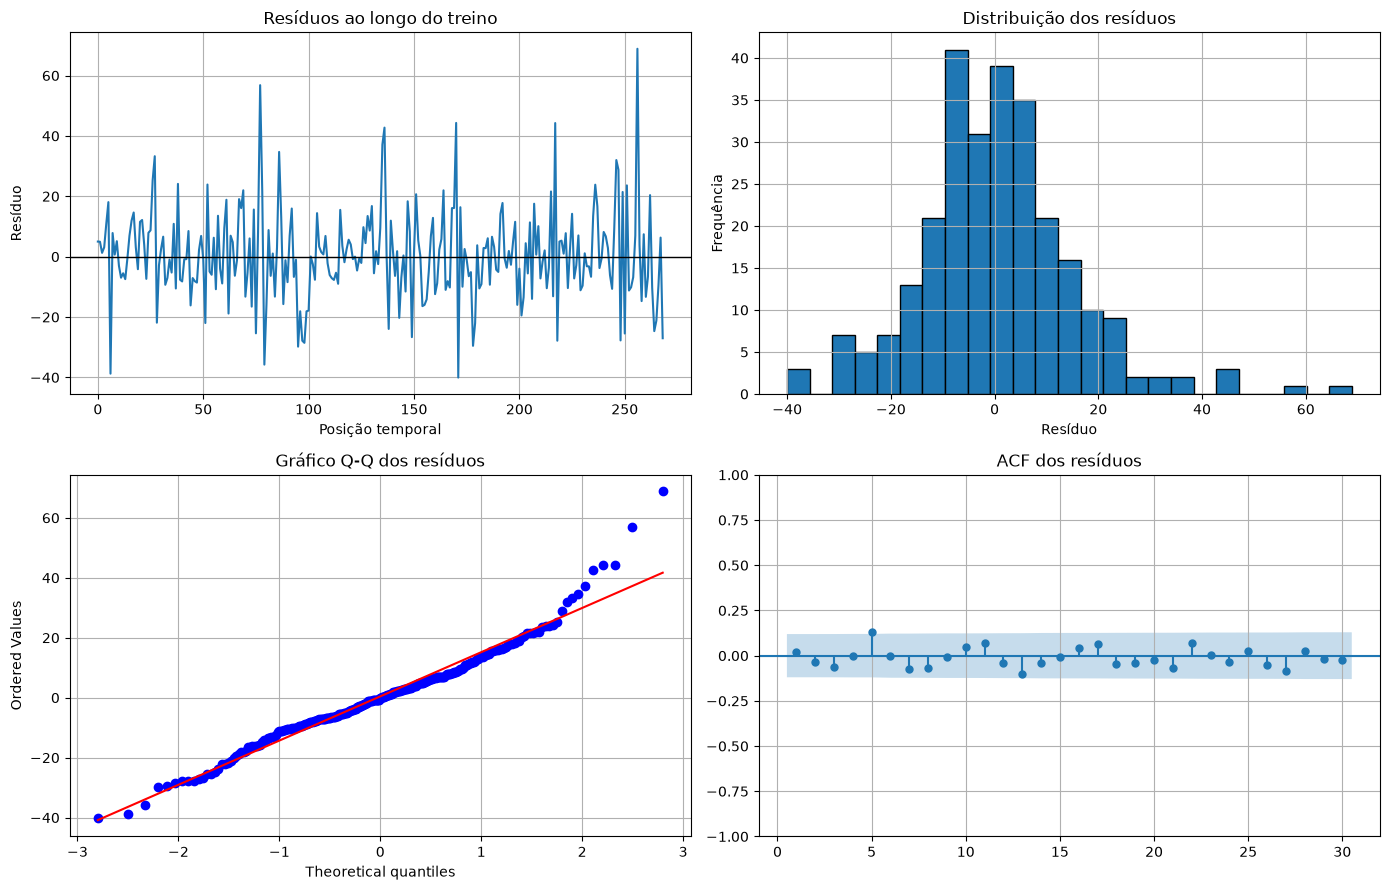

In [19]:
residuos = pd.Series(np.asarray(modelo_treino.resid).reshape(-1)).dropna()

fig, eixos = plt.subplots(2, 2, figsize=(14, 9))
eixos[0, 0].plot(np.arange(len(residuos)), residuos)
eixos[0, 0].axhline(0, color="black", linewidth=1)
eixos[0, 0].set(title="Resíduos ao longo do treino", xlabel="Posição temporal", ylabel="Resíduo")

eixos[0, 1].hist(residuos, bins=25, edgecolor="black")
eixos[0, 1].set(title="Distribuição dos resíduos", xlabel="Resíduo", ylabel="Frequência")

from scipy import stats
stats.probplot(residuos, dist="norm", plot=eixos[1, 0])
eixos[1, 0].set_title("Gráfico Q-Q dos resíduos")

lags_acf = min(30, max(5, len(residuos)//4))
plot_acf(residuos, lags=lags_acf, ax=eixos[1, 1], zero=False)
eixos[1, 1].set_title("ACF dos resíduos")

plt.tight_layout()
plt.show()

In [20]:
p_escolhido, d_escolhido, q_escolhido = ordem_escolhida
# O teste de Ljung–Box verifica a hipótese nula de ausência de autocorrelação
# conjunta até cada defasagem. model_df ajusta os graus de liberdade pelos
# parâmetros AR e MA estimados.
max_lag_lb = min(20, len(residuos) - 1)
lags_lb = [lag for lag in [10, 20] if lag <= max_lag_lb and lag > (p_escolhido + q_escolhido)]

if lags_lb:
    resultado_lb = acorr_ljungbox(residuos, lags=lags_lb, model_df=p_escolhido + q_escolhido, return_df=True)
    display(resultado_lb)
else:
    print("Não há defasagens suficientes para aplicar Ljung–Box com os graus de liberdade deste modelo.")

,lb_stat,lb_pvalue
10,9.530646,0.008520
20,17.814477,0.121441


### Como interpretar o Ljung–Box

- **Hipótese nula:** não há autocorrelação residual conjunta até a defasagem avaliada.
- **p-valor pequeno** (por exemplo, abaixo de 0,05): rejeitamos a hipótese nula; há evidência de autocorrelação que o modelo não capturou.
- **p-valor maior:** não rejeitamos a hipótese nula; isso não prova independência, apenas indica que o teste não encontrou evidência suficiente.

Se a ACF dos resíduos mostrar picos persistentes ou o Ljung–Box indicar autocorrelação, a equipe deve considerar ampliar/rever a ordem, testar transformações ou discutir modelos que representem melhor a periodicidade. Não aumente `p` e `q` indefinidamente apenas para eliminar um p-valor pequeno.

## 7. Avaliação fora da amostra: previsão de um passo à frente

O procedimento abaixo imita uma aplicação real em que, a cada ano, o valor observado do ano anterior já está disponível:

1. ajusta o ARIMA usando todo o histórico disponível;
2. prevê somente o ano seguinte;
3. registra a previsão;
4. incorpora o valor real desse ano ao histórico;
5. repete para o próximo ano.

A ordem ARIMA não é reescolhida durante o teste. Ela foi selecionada antes, usando somente o treino. Os parâmetros numéricos são reestimados em cada origem temporal (`refit`). Este desenho é chamado de avaliação de origem móvel/expansiva de um passo à frente.

In [21]:
historico = treino.to_numpy(dtype=float).copy()
previsoes_arima = []
convergencias_rolling = []
limites_inferiores = []
limites_superiores = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for ano, valor_real in teste.items():
        ajuste_atual = ARIMA(
            historico,
            order=ordem_escolhida,
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(method_kwargs={"maxiter": 200})
        convergencias_rolling.append(getattr(ajuste_atual, "mle_retvals", {}).get("converged", np.nan))
        previsao = ajuste_atual.get_forecast(steps=1)
        previsoes_arima.append(float(np.asarray(previsao.predicted_mean).reshape(-1)[0]))
        intervalo = np.asarray(previsao.conf_int()).reshape(-1, 2)[0]
        limites_inferiores.append(float(intervalo[0]))
        limites_superiores.append(float(intervalo[1]))

        # O valor real só é incorporado depois de produzir a previsão daquele ano.
        historico = np.append(historico, float(valor_real))

resultado_previsoes = pd.DataFrame({
    "ano": teste.index.to_numpy(),
    "real": teste.to_numpy(dtype=float),
    "previsao_arima": previsoes_arima,
    "limite_inferior_95": limites_inferiores,
    "limite_superior_95": limites_superiores
}).set_index("ano")

display(resultado_previsoes.head(10).round(2))
print("Previsões produzidas:", len(resultado_previsoes))
print("Reajustes com convergência reportada:", sum(valor is True for valor in convergencias_rolling), "de", len(convergencias_rolling))

,real,previsao_arima,limite_inferior_95,limite_superior_95
ano,,,,
1969,105.5,114.87,85.65,144.10
1970,104.5,98.09,68.91,127.28
1971,66.6,92.65,63.51,121.79
1972,68.9,31.87,2.62,61.12
1973,38.0,55.45,25.87,85.03
1974,34.5,23.47,-6.12,53.06
1975,15.5,30.56,1.00,60.12
1976,12.6,28.20,-1.31,57.70
1977,27.5,26.16,-3.36,55.68


Previsões produzidas: 40
Reajustes com convergência reportada: 40 de 40


## 8. Métricas e modelos de referência simples

Calcularemos as métricas solicitadas no projeto:

- **MAE:** erro absoluto médio, na unidade original da série.
- **RMSE:** raiz do erro quadrático médio; penaliza mais os erros grandes.
- **MAPE:** erro percentual absoluto médio. É indefinido quando o valor real é zero e instável quando ele está muito próximo de zero. Por isso, o código informa quantos pontos entraram no cálculo.
- **R²:** proporção de variabilidade explicada em relação à média do conjunto de teste. Pode ser negativo quando o modelo é pior do que prever a média do teste.

Também incluiremos duas referências simples: persistência (usar o último valor observado) e sazonal ingênuo de 11 anos (usar o valor de 11 anos antes). Elas ajudam a verificar se o ARIMA agrega valor em relação a regras básicas.

In [22]:
# Referências calculadas de forma temporal, sem usar observações futuras.
historico_base = treino.to_numpy(dtype=float).copy()
previsao_persistencia = []
previsao_11_anos = []
for valor_real in teste.to_numpy(dtype=float):
    previsao_persistencia.append(float(historico_base[-1]))
    previsao_11_anos.append(float(historico_base[-11]))
    historico_base = np.append(historico_base, valor_real)


def calcular_metricas(y_real, y_previsto):
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)
    mascara_mape = np.abs(y_real) > 1e-8
    mape = (
        mean_absolute_percentage_error(y_real[mascara_mape], y_previsto[mascara_mape]) * 100
        if mascara_mape.any() else np.nan
    )
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "MAPE (%)": mape,
        "Pontos no MAPE": int(mascara_mape.sum()),
        "R²": r2_score(y_real, y_previsto)
    }

metricas = pd.DataFrame({
    "ARIMA": calcular_metricas(resultado_previsoes["real"], resultado_previsoes["previsao_arima"]),
    "Persistência": calcular_metricas(resultado_previsoes["real"], previsao_persistencia),
    "Sazonal ingênuo (11 anos)": calcular_metricas(resultado_previsoes["real"], previsao_11_anos)
}).T

display(metricas.round(3))
print("Observação: o MAPE exclui apenas valores reais exatamente iguais a zero (ou numericamente muito próximos de zero).")

,MAE,RMSE,MAPE (%),Pontos no MAPE,R²
ARIMA,14.972,18.257,58.060,40.0,0.858
Persistência,22.745,29.889,51.769,40.0,0.618
Sazonal ingênuo (11 anos),25.725,33.961,57.996,40.0,0.507


Observação: o MAPE exclui apenas valores reais exatamente iguais a zero (ou numericamente muito próximos de zero).


## 9. Visualização das previsões no período de teste

O gráfico principal compara os valores reais e as previsões de um passo à frente. A faixa de 95% é o intervalo preditivo do ARIMA para cada ano, calculado no momento daquela previsão.

Observe especialmente se o modelo acompanha os períodos de subida e descida e se tende a suavizar ou atrasar os picos. Um modelo pode apresentar erro médio razoável e ainda falhar em reproduzir a amplitude de máximos e mínimos.

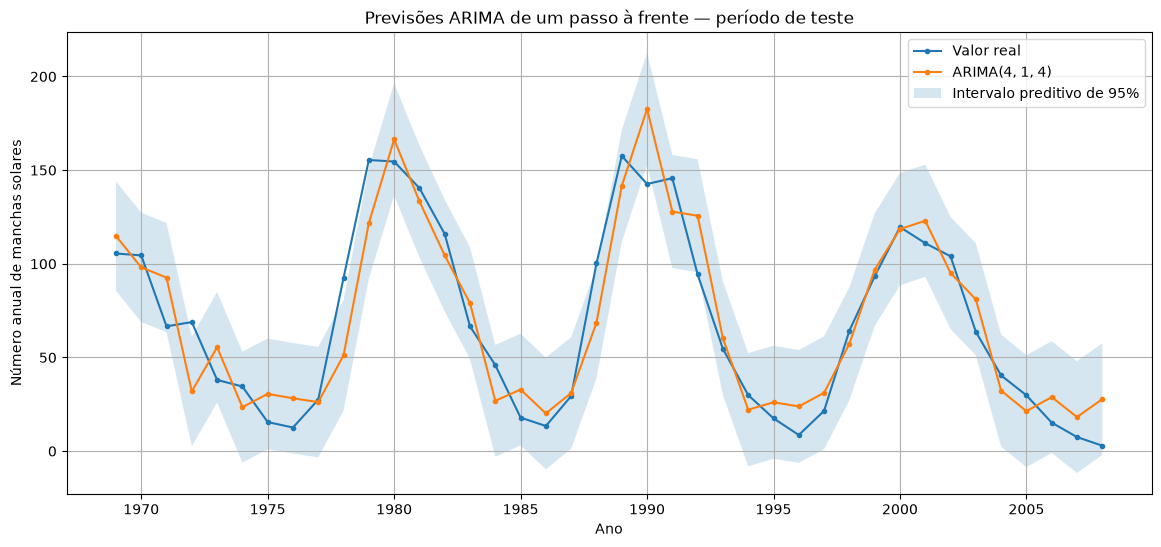

In [23]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(resultado_previsoes.index, resultado_previsoes["real"], marker="o", markersize=3, label="Valor real")
ax.plot(resultado_previsoes.index, resultado_previsoes["previsao_arima"], marker="o", markersize=3, label=f"ARIMA{ordem_escolhida}")
ax.fill_between(
    resultado_previsoes.index,
    resultado_previsoes["limite_inferior_95"],
    resultado_previsoes["limite_superior_95"],
    alpha=0.18,
    label="Intervalo preditivo de 95%"
)
ax.set(title="Previsões ARIMA de um passo à frente — período de teste", xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.show()

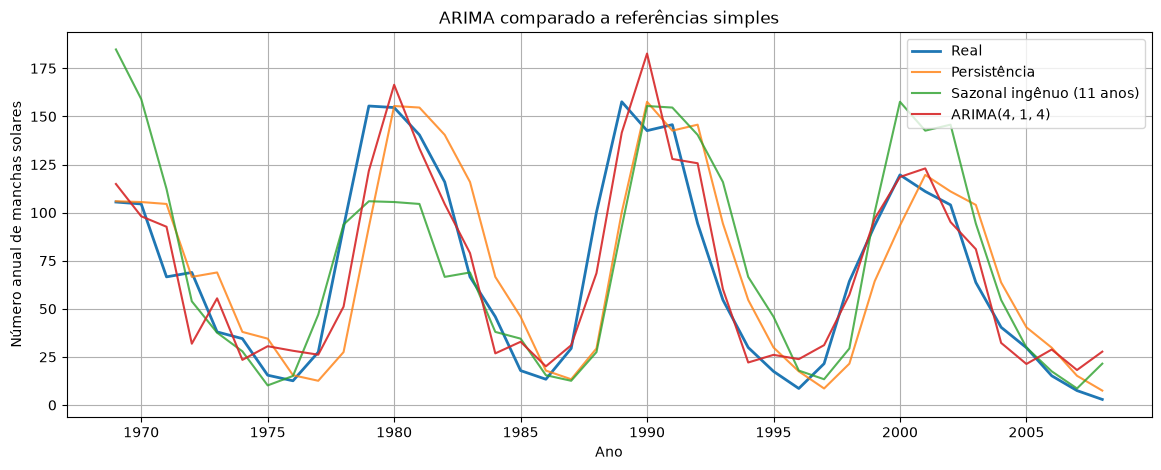

In [24]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(resultado_previsoes.index, resultado_previsoes["real"], label="Real", linewidth=2)
ax.plot(resultado_previsoes.index, previsao_persistencia, label="Persistência", alpha=0.8)
ax.plot(resultado_previsoes.index, previsao_11_anos, label="Sazonal ingênuo (11 anos)", alpha=0.8)
ax.plot(resultado_previsoes.index, resultado_previsoes["previsao_arima"], label=f"ARIMA{ordem_escolhida}", alpha=0.9)
ax.set(title="ARIMA comparado a referências simples", xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.show()

## 10. Erros ao longo do tempo e anos mais difíceis

O erro de previsão é `real - previsto`. Erros positivos indicam que o modelo subestimou o valor real; erros negativos indicam superestimação. A tabela abaixo destaca os anos com maior erro absoluto, útil para investigar se os erros se concentram perto de picos, vales ou mudanças rápidas.

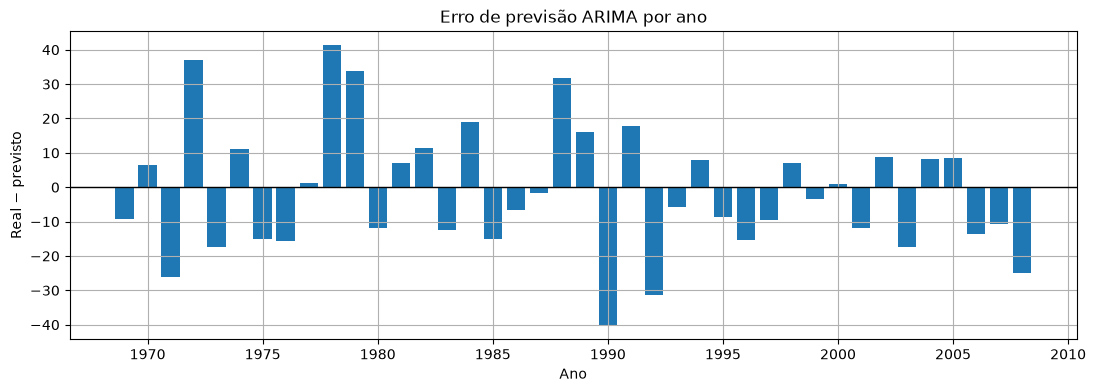

,real,previsao_arima,limite_inferior_95,limite_superior_95,erro,erro_absoluto
ano,,,,,,
1978,92.5,51.11,21.64,80.57,41.39,41.39
1990,142.6,182.67,152.77,212.56,-40.07,40.07
1972,68.9,31.87,2.62,61.12,37.03,37.03
1979,155.4,121.70,91.97,151.43,33.70,33.70
1988,100.2,68.52,38.80,98.24,31.68,31.68
1992,94.3,125.65,95.47,155.84,-31.35,31.35
1971,66.6,92.65,63.51,121.79,-26.05,26.05
2008,2.9,27.75,-2.08,57.57,-24.85,24.85
1984,45.9,26.85,-2.96,56.65,19.05,19.05


In [25]:
resultado_previsoes["erro"] = resultado_previsoes["real"] - resultado_previsoes["previsao_arima"]
resultado_previsoes["erro_absoluto"] = resultado_previsoes["erro"].abs()

fig, ax = plt.subplots(figsize=(13, 4))
ax.axhline(0, color="black", linewidth=1)
ax.bar(resultado_previsoes.index, resultado_previsoes["erro"])
ax.set(title="Erro de previsão ARIMA por ano", xlabel="Ano", ylabel="Real − previsto")
plt.show()

display(resultado_previsoes.sort_values("erro_absoluto", ascending=False).head(10).round(2))

## 11. Exportação dos resultados

Salvaremos as tabelas principais em CSV. Os arquivos serão criados na pasta em que o Jupyter estiver sendo executado. Isso facilita incluir os números no relatório e compará-los posteriormente com o modelo de Machine Learning.

In [26]:
tabela_busca.to_csv("sunspots_busca_arima.csv", index=False)
resultado_previsoes.to_csv("sunspots_previsoes_arima.csv")
metricas.to_csv("sunspots_metricas_arima.csv")
print("Arquivos CSV exportados:")
print("- sunspots_busca_arima.csv")
print("- sunspots_previsoes_arima.csv")
print("- sunspots_metricas_arima.csv")

Arquivos CSV exportados:
- sunspots_busca_arima.csv
- sunspots_previsoes_arima.csv
- sunspots_metricas_arima.csv


## 12. Perguntas para a equipe

Respondam com base nos resultados efetivamente obtidos na execução:

1. Qual ordem ARIMA foi selecionada pelo AIC? Qual foi o AIC e como ela se compara às alternativas?
2. O ajuste convergiu? Houve modelos que falharam na busca?
3. Os resíduos parecem apresentar padrão temporal? O que mostra a ACF dos resíduos?
4. O teste de Ljung–Box rejeitou a hipótese nula em alguma das defasagens? O que isso sugere?
5. Qual foi o MAE, RMSE, MAPE e R² do ARIMA no teste?
6. O ARIMA superou a persistência e o modelo sazonal ingênuo de 11 anos?
7. Em quais anos ocorreram os maiores erros? Eles estão associados a picos ou vales do ciclo?
8. O intervalo preditivo de 95% foi suficientemente amplo para conter os valores reais? Lembrem-se de que a cobertura observada pode diferir de 95% em uma amostra pequena.
9. Que limitações do ARIMA devem ser consideradas antes de compará-lo com Random Forest ou MLP?

### Modelo de parágrafo para o relatório

> Foi ajustado um modelo ARIMA de ordem **(preencher)**, selecionado por AIC com dados de treinamento do período **(preencher)**. O desempenho foi avaliado nos anos **(preencher)** por previsões de um passo à frente, com atualização do histórico após cada observação real. As métricas obtidas foram MAE = **(preencher)**, RMSE = **(preencher)**, MAPE = **(preencher)** e R² = **(preencher)**. A análise dos resíduos mostrou **(preencher)**. Em comparação com os modelos de referência, o ARIMA **(preencher)**. Esses resultados sugerem **(interpretação da equipe)**, respeitando as limitações de uma série anual com ciclos cuja duração e amplitude variam.

## 13. Próxima etapa: Random Forest

O Notebook 04 implementará um modelo de Machine Learning. Para manter a comparação justa:

- usaremos a mesma base e a mesma divisão cronológica;
- o teste permanecerá nos mesmos 40 anos;
- criaremos atributos defasados (lags), incluindo pelo menos 11 ou 12 anos anteriores;
- faremos o ajuste sem embaralhar a sequência temporal;
- avaliaremos com as mesmas métricas e, preferencialmente, o mesmo esquema de previsão de um passo à frente.

**Importante:** o melhor modelo não será necessariamente aquele que tem menor erro em uma única métrica. Também importam a estabilidade, os resíduos, os picos e vales que consegue representar e a clareza da interpretação.